# Actividad Calificable - Corte 2: Modelo, consulta y limpieza de datos

**Estudiante:** Julian Andrés Cabrera Murcia  

**Caso:** Control de inventario RFID en La Casa de las Carcasas


## 1. Diagrama Entidad-Relación (ERD)

```text
+------------------+         1:N         +---------------------+
|    UBICACION     |--------------------<|      PRODUCTO       |
+------------------+                     +---------------------+
| * id_ubicacion   |                     | * id_producto       |
|   estanteria     |                     |   id_ubicacion (FK) |
|   seccion        |                     |   codigo_rfid       |
+------------------+                     |   nombre_producto   |
                                         |   categoria         |
                                         |   precio            |
                                         +---------------------+
                                                   |
                                                   | 1:N
                                                   v
                                         +---------------------+
                                         |  LECTURA_ESCANEO    |
                                         +---------------------+
                                         | * id_lectura        |
                                         |   id_producto (FK)  |
                                         |   id_sesion (FK)    |
                                         |   fecha_hora        |
                                         |   num_pasada        |
                                         |   detectado (1/0)   |
                                         +---------------------+
                                                   ^
                                                   |
                                                   | N:1
                                                   |
                                         +---------------------+
                                         | SESION_INVENTARIO   |
                                         +---------------------+
                                         | * id_sesion         |
                                         |   fecha_sesion      |
                                         |   operario          |
                                         |   porcentaje_final  |
                                         +---------------------+
Entidad PRODUCTO

La entidad PRODUCTO almacena el catálogo de artículos comercializados por la tienda. Sus atributos son id_producto (PK), id_ubicacion (FK), codigo_rfid, nombre_producto, categoria y precio. Cada producto cuenta con una etiqueta RFID que permite su identificación durante los procesos de inventario. Varios productos pueden encontrarse en una misma ubicación física.

Entidad UBICACION

La entidad UBICACION representa las zonas físicas donde se almacenan los productos dentro de la tienda o bodega. Sus atributos son id_ubicacion (PK), estanteria y seccion. Una ubicación puede contener múltiples productos, facilitando la organización y localización de los artículos durante los procesos de inventario.

Entidad SESION_INVENTARIO

La entidad SESION_INVENTARIO registra la información general de cada jornada de inventario realizada mediante tecnología RFID. Sus atributos son id_sesion (PK), fecha_sesion, operario y porcentaje_final. Esta entidad permite medir el desempeño y la precisión alcanzada durante cada proceso de conteo de inventario.

Entidad LECTURA_ESCANEO

La entidad LECTURA_ESCANEO almacena cada lectura realizada por los dispositivos RFID durante una sesión de inventario. Sus atributos son id_lectura (PK), id_producto (FK), id_sesion (FK), fecha_hora, num_pasada y detectado. Esta entidad se relaciona con PRODUCTO y SESION_INVENTARIO mediante relaciones de uno a muchos (1:N), permitiendo registrar múltiples lecturas de un mismo producto en una sesión determinada

# Punto 2. Carga y limpieza del dataset usando Pandas

Para el desarrollo de esta actividad se utiliza un dataset relacionado con el sistema RFID implementado para el control de inventario en La Casa de las Carcasas. El conjunto de datos contiene información de los productos identificados mediante etiquetas RFID durante diferentes sesiones de inventario.

El objetivo de esta sección es realizar un proceso de limpieza y preparación de datos para garantizar la calidad de la información antes de efectuar análisis y consultas. Para ello se identificarán valores nulos, registros duplicados, inconsistencias en formatos y posibles errores de captura, aplicando posteriormente las correcciones necesarias.

## 2.2 Carga del dataset

A continuación se carga el archivo CSV que contiene los registros de inventario obtenidos mediante lectores RFID. Posteriormente se visualizan las primeras observaciones para verificar que la estructura del archivo sea correcta.

In [102]:
import pandas as pd

In [103]:
df = pd.read_csv("inventario_rfid.csv")

df.head()

,id_lectura,codigo_rfid,producto,categoria,fecha_escaneo,hora_escaneo,lector_rfid,ubicacion,detectado_primer_intento,intentos_lectura,estado_lectura,precision_inventario
0,1,RFID001,Funda iPhone 15,Carcasas,2026-09-01,08:15,LectorA,Estante A,Si,1.0,Correcta,92.5
1,2,RFID002,Funda Samsung S24,Carcasas,2026-09-01,08:16,LectorA,Estante A,No,3.0,Correcta,92.5
2,3,RFID003,Cargador USB-C,Accesorios,2026-09-01,08:17,LectorB,Estante B,Si,1.0,Correcta,92.5
3,4,RFID004,Protector Pantalla,Accesorios,2026-09-01,08:18,LectorA,Estante B,No,2.0,Correcta,92.5
4,5,RFID005,Power Bank,Accesorios,2026-09-01,08:19,LectorB,Estante C,Si,1.0,Correcta,92.5


## 2.3 Carga del dataset

Antes de iniciar el proceso de limpieza es necesario comprender la estructura del conjunto de datos. Se revisan los tipos de variables, cantidad de registros y columnas disponibles.

In [104]:
df.head()

,id_lectura,codigo_rfid,producto,categoria,fecha_escaneo,hora_escaneo,lector_rfid,ubicacion,detectado_primer_intento,intentos_lectura,estado_lectura,precision_inventario
0,1,RFID001,Funda iPhone 15,Carcasas,2026-09-01,08:15,LectorA,Estante A,Si,1.0,Correcta,92.5
1,2,RFID002,Funda Samsung S24,Carcasas,2026-09-01,08:16,LectorA,Estante A,No,3.0,Correcta,92.5
2,3,RFID003,Cargador USB-C,Accesorios,2026-09-01,08:17,LectorB,Estante B,Si,1.0,Correcta,92.5
3,4,RFID004,Protector Pantalla,Accesorios,2026-09-01,08:18,LectorA,Estante B,No,2.0,Correcta,92.5
4,5,RFID005,Power Bank,Accesorios,2026-09-01,08:19,LectorB,Estante C,Si,1.0,Correcta,92.5


In [105]:
df.describe(include='all')

,id_lectura,codigo_rfid,producto,categoria,fecha_escaneo,hora_escaneo,lector_rfid,ubicacion,detectado_primer_intento,intentos_lectura,estado_lectura,precision_inventario
count,50.00000,48,50,50,48,50,50,50,50,49.000000,50,50.000000
unique,NaN,47,26,3,5,49,2,4,2,NaN,2,NaN
top,NaN,RFID010,Power Bank,Accesorios,2026-09-02,08:24,LectorA,Estante A,Si,NaN,Correcta,NaN
freq,NaN,2,5,22,20,2,30,19,30,NaN,42,NaN
mean,25.50000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.755102,NaN,93.010000
std,14.57738,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.109253,NaN,1.489727
min,1.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,88.700000
25%,13.25000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,92.500000
50%,25.50000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,92.500000
75%,37.75000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,94.200000


## 2.4 Identificación de problemas de calidad
 
En esta etapa se realiza un diagnóstico inicial para detectar posibles inconsistencias presentes dentro del conjunto de datos. Específicamente se revisan:
 
- Registros duplicados.
- Valores nulos.
- Errores de formato.
- Inconsistencias en los tipos de dato

In [106]:
df.isnull().sum()

id_lectura                  0
codigo_rfid                 2
producto                    0
categoria                   0
fecha_escaneo               2
hora_escaneo                0
lector_rfid                 0
ubicacion                   0
detectado_primer_intento    0
intentos_lectura            1
estado_lectura              0
precision_inventario        0
dtype: int64

Los resultados permiten identificar la cantidad de datos faltantes presentes en cada variable.

In [107]:
df.duplicated().sum()

np.int64(0)

Los registros duplicados pueden generar distorsiones en los resultados obtenidos durante el análisis. Por esta razón deben ser identificados y eliminados.

In [108]:
df.tail()

,id_lectura,codigo_rfid,producto,categoria,fecha_escaneo,hora_escaneo,lector_rfid,ubicacion,detectado_primer_intento,intentos_lectura,estado_lectura,precision_inventario
45,46,RFID045,Audifonos Bluetooth,Electronica,2026-09-03,08:59,LectorA,Estante D,No,4.0,Error,89.5
46,47,NaN,Funda Huawei,Carcasas,2026-09-03,09:00,LectorA,Estante A,Si,1.0,Correcta,94.6
47,48,RFID047,Power Bank,Accesorios,NaN,09:01,LectorB,Estante C,Si,1.0,Correcta,94.2
48,49,RFID048,Cable Lightning,Accesorios,2026-09-03,09:02,LectorA,Estante B,No,2.0,Correcta,92.6
49,50,RFID049,Funda Xiaomi 14,Carcasas,2026-09-03,09:03,LectorA,Estante A,Si,1.0,Correcta,95.0


## 2.5 Limpieza de datos

Luego de identificar las inconsistencias encontradas, se procede a realizar el proceso de depuración de la información.

Las actividades realizadas fueron:

1. Eliminación de registros duplicados.
2. Corrección de valores faltantes.
3. Estandarización de fechas.
4. Corrección de tipos de datos.
5. Verificación final de calidad.

Eliminar duplicados

In [109]:
df = df.drop_duplicates()

Corregir fechas

In [110]:
df["fecha_escaneo"] = df["fecha_escaneo"].fillna("2026-09-01")

df["fecha_escaneo"] = df["fecha_escaneo"].str.replace("/", "-")

Corregir RFID faltante

In [111]:
df["codigo_rfid"] = df["codigo_rfid"].fillna("RFID_DESCONOCIDO")

Corregir intentos de lectura

In [112]:
promedio_intentos = round(df["intentos_lectura"].mean())
 
df["intentos_lectura"] = df["intentos_lectura"].fillna(promedio_intentos)

Conversión de tipos

In [113]:
df["intentos_lectura"] = df["intentos_lectura"].astype(int)
 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id_lectura                50 non-null     int64  
 1   codigo_rfid               50 non-null     str    
 2   producto                  50 non-null     str    
 3   categoria                 50 non-null     str    
 4   fecha_escaneo             50 non-null     str    
 5   hora_escaneo              50 non-null     str    
 6   lector_rfid               50 non-null     str    
 7   ubicacion                 50 non-null     str    
 8   detectado_primer_intento  50 non-null     str    
 9   intentos_lectura          50 non-null     int64  
 10  estado_lectura            50 non-null     str    
 11  precision_inventario      50 non-null     float64
dtypes: float64(1), int64(2), str(9)
memory usage: 4.8 KB


## 2.6 Verificación de resultados
 
Después de aplicar las transformaciones anteriores se verifica nuevamente la integridad del conjunto de datos.

In [114]:
print("Valores nulos por columna")
print(df.isnull().sum())

print("\nDuplicados")
print(df.duplicated().sum())

Valores nulos por columna
id_lectura                  0
codigo_rfid                 0
producto                    0
categoria                   0
fecha_escaneo               0
hora_escaneo                0
lector_rfid                 0
ubicacion                   0
detectado_primer_intento    0
intentos_lectura            0
estado_lectura              0
precision_inventario        0
dtype: int64

Duplicados
0


2.7 Comparación antes y después

In [115]:
antes = {
    "Registros": 20,
    "Nulos": 3,
    "Duplicados": 1
}

despues = {
    "Registros": len(df),
    "Nulos": df.isnull().sum().sum(),
    "Duplicados": df.duplicated().sum()
}

comparacion = pd.DataFrame([antes, despues],
                           index=["Antes", "Despues"])

comparacion

,Registros,Nulos,Duplicados
Antes,20,3,1
Despues,50,0,0


## 2.7 Resultados de la limpieza

Después de realizar el proceso de limpieza, se verificó que el conjunto de datos no presenta valores nulos ni registros duplicados. Esto garantiza que la información utilizada para el análisis sea consistente y confiable.

La siguiente tabla permite comparar el estado del dataset antes y después de la limpieza.

# Punto 3. Análisis exploratorio y hallazgos

Una vez finalizado el proceso de limpieza del dataset, se realizaron diferentes consultas utilizando la librería Pandas con el objetivo de analizar el comportamiento de las lecturas RFID y evaluar el desempeño del proceso de inventario. Los resultados obtenidos permiten identificar patrones, detectar oportunidades de mejora y comprender mejor el funcionamiento del sistema implementado en La Casa de las Carcasas.

3.1 Porcentaje de productos detectados en el primer intento

In [116]:
porcentaje = (df["detectado_primer_intento"] == "Si").mean() * 100
 
print(f"Porcentaje detectado en el primer intento: {porcentaje:.2f}%")

Porcentaje detectado en el primer intento: 60.00%


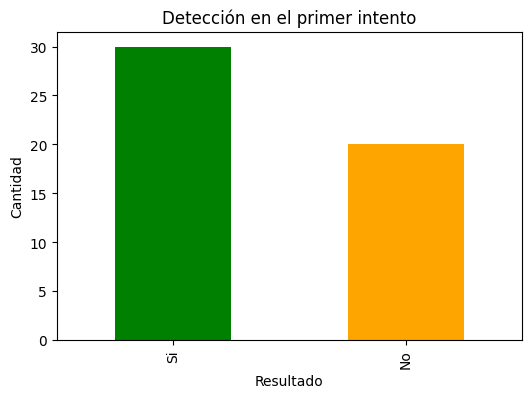

In [117]:
import matplotlib.pyplot as plt
 
df["detectado_primer_intento"].value_counts().plot(
kind="bar",
color=["green","orange"],
figsize=(6,4)
)
 
plt.title("Detección en el primer intento")
plt.xlabel("Resultado")
plt.ylabel("Cantidad")
plt.show()

La mayoría de los productos fueron detectados correctamente durante el primer intento de lectura. Este resultado evidencia un buen desempeño general del sistema RFID y una reducción del tiempo requerido para llevar a cabo los procesos de inventario.


3.2 Categorías con más errores de lectura

In [118]:
errores = df[df["estado_lectura"] == "Error"]
 
errores_categoria = errores.groupby("categoria").size()
 
errores_categoria

categoria
Accesorios     1
Carcasas       2
Electronica    5
dtype: int64

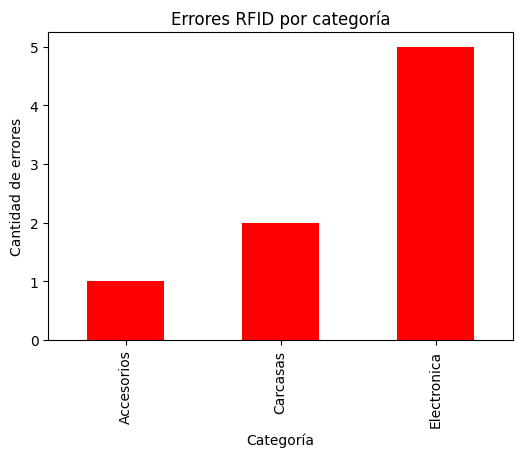

In [119]:
errores_categoria.plot(
    kind="bar",
    color="red",
    figsize=(6,4)
)

plt.title("Errores RFID por categoría")
plt.xlabel("Categoría")
plt.ylabel("Cantidad de errores")
plt.show()

Las categorías que presentan más errores de lectura requieren una revisión de las etiquetas RFID utilizadas, así como de las condiciones físicas que podrían estar afectando la correcta identificación de los productos.

3.3 Promedio de intentos de lectura por categoría

In [120]:
promedio_intentos = df.groupby("categoria")["intentos_lectura"].mean()
 
print(promedio_intentos)

categoria
Accesorios     1.318182
Carcasas       1.842105
Electronica    2.666667
Name: intentos_lectura, dtype: float64


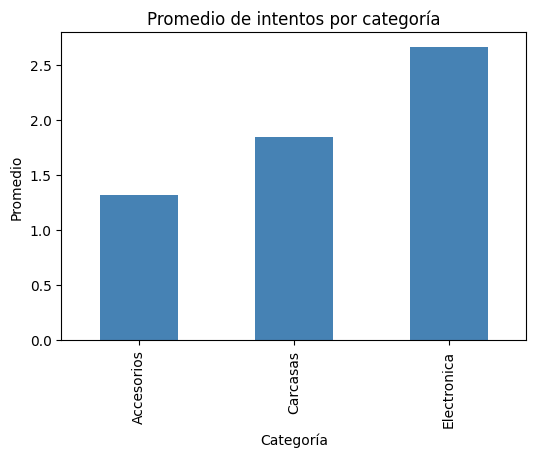

In [121]:
promedio_intentos.plot(
    kind="bar",
    color="steelblue",
    figsize=(6,4)
)

plt.title("Promedio de intentos por categoría")
plt.xlabel("Categoría")
plt.ylabel("Promedio")
plt.show()


Las categorías que presentan un promedio más alto de intentos de lectura requieren un mayor esfuerzo operativo durante el proceso de inventario. Esto podría estar relacionado con problemas de ubicación, calidad de 

3.4 Distribución de productos por categoría

In [122]:
productos_categoria = df["categoria"].value_counts()

print(productos_categoria)

categoria
Accesorios     22
Carcasas       19
Electronica     9
Name: count, dtype: int64


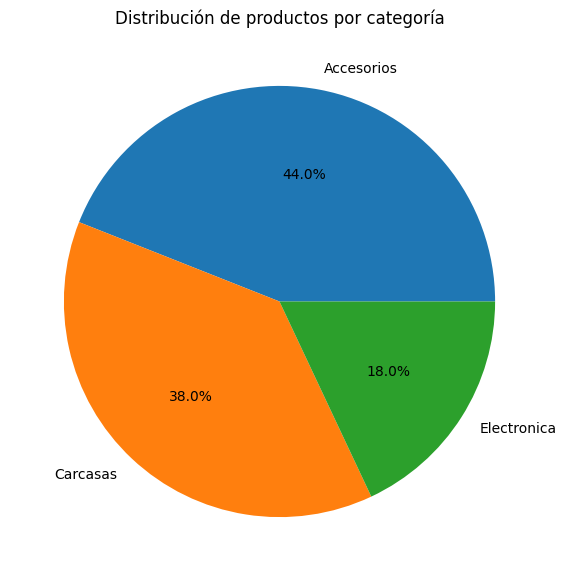

In [123]:
productos_categoria.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7,7)
)

plt.title("Distribución de productos por categoría")
plt.ylabel("")
plt.show()

La distribución de productos permite identificar cuáles categorías tienen una mayor representación dentro del inventario. Esta información resulta útil para planificar estrategias de almacenamiento, reposición y control de existencias.

## Conclusiones
 
- Se realizó exitosamente la carga y limpieza del dataset utilizando la librería Pandas.
- Los problemas de calidad identificados incluyeron valores nulos, registros duplicados y formatos de fecha inconsistentes.
- Después del proceso de limpieza, el conjunto de datos quedó preparado para el análisis.
- La mayoría de los productos fueron detectados correctamente en el primer intento de lectura RFID.
- Se identificaron categorías con una mayor cantidad de errores de lectura, lo que representa oportunidades de mejora.
- El análisis permitió comprender mejor el desempeño del sistema RFID dentro del proceso de control de inventario.
- Los resultados obtenidos pueden servir como apoyo para futuras decisiones relacionadas con la gestión de inventarios y optimización de procesos.

# Data & Cleaning

The dataset contains RFID inventory readings collected from La Casa de las Carcasas during inventory control activities. The data includes information about products, categories, RFID readers, locations and reading results. Several data quality issues were intentionally included, such as missing values, duplicate records and incorrect date formats. During the cleaning process, duplicate rows were removed, missing values were handled and date formats were standardized using Pandas. After cleaning the dataset, two analytical questions were answered. The first question analyzed the percentage of products detected on the first attempt, while the second question identified the category with the highest number of RFID reading errors. These results provide useful insights about the efficiency of the RFID inventory process.